In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uncertainties

In [12]:
df = pd.read_csv("run_20K.csv")
df.head()

,V_Copper,V_Sapphire,time,sensor_temperature,temperature_setpoint,iTC_P_param,iTC_I_param,iTC_D_param
0,-0.000006,-1.565693e-06,0.000000,20.0003,20.0,2.0,1.0,0.0
1,-0.000005,-1.622204e-06,0.234904,20.0039,20.0,2.0,1.0,0.0
2,-0.000005,-1.019910e-06,0.484475,20.0058,20.0,2.0,1.0,0.0
3,-0.000006,-8.441198e-07,0.732841,20.0043,20.0,2.0,1.0,0.0
4,-0.000006,-1.564694e-06,0.992402,19.9998,20.0,2.0,1.0,0.0


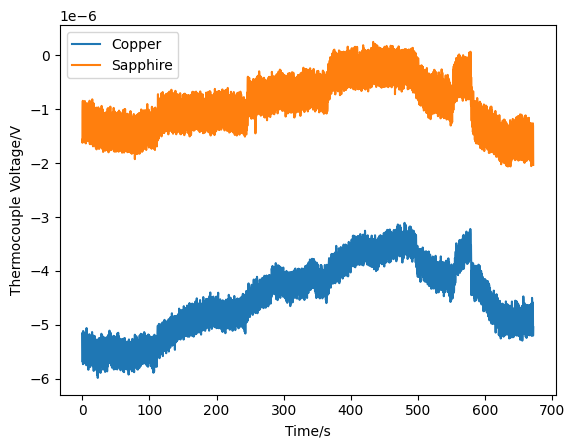

In [13]:
time = df['time']
v_cop = df['V_Copper']
v_sap = df['V_Sapphire']

plt.plot(time, v_cop, label = 'Copper')
plt.plot(time, v_sap, label = 'Sapphire')
plt.legend()
plt.xlabel("Time/s")
plt.ylabel("Thermocouple Voltage/V")
plt.show()

In [ ]:
windows15K = {
    "V_Copper":   [(0, 118), (155, 228), (260, 395), (440, 612), (660, 770)],
    "V_Sapphire": [(0, 118), (145, 228), (255, 395), (425, 612), (660, 770)],
}

windows20K = {
    "V_Copper":   [(0, 105), (175, 238), (285, 365), (420, 498), (630, 670)],
    "V_Sapphire": [(0, 105), (140, 238), (270, 365), (390, 498), (620, 670)],
}

windows = windows20K

v_avg = {}
v_std = {}

for material, times in windows.items():
    print(material)
    v_avg[material] = []
    v_std[material] = []
    for start, end in times:
        in_window = (time >= start) & (time <= end)
        average = df.loc[in_window, material].mean()
        std = df.loc[in_window, material].std()
        v_avg[material].append(average)
        v_std[material].append(std)
        print(f"  {start}-{end} s: {average:.4e} +- {std:.4e} V")

V_Copper
  0-118 s: -5.4911e-06 +- 2.4882e-07 V
  155-228 s: -4.8194e-06 +- 2.4318e-07 V
  260-395 s: -4.1737e-06 +- 2.8294e-07 V
  440-612 s: -3.8758e-06 +- 4.1294e-07 V
  660-770 s: -4.8943e-06 +- 2.5028e-07 V
V_Sapphire
  0-118 s: -1.3797e-06 +- 3.1596e-07 V
  145-228 s: -1.0602e-06 +- 3.0943e-07 V
  255-395 s: -6.2301e-07 +- 3.4439e-07 V
  425-612 s: -5.7948e-07 +- 4.8854e-07 V
  660-770 s: -1.6123e-06 +- 3.0330e-07 V


In [15]:
baseline = {
    "V_Copper": v_avg["V_Copper"][0],
    "V_Sapphire": v_avg["V_Sapphire"][0]
}

v_avg_adj = {}

for material in v_avg.keys():
    v_avg_adj[material] = []
    #print(material)
    for i in range(1, len(v_avg[material])-1):
        v_avg_adj[material].append(v_avg[material][i]-baseline[material])
for material, values in v_avg_adj.items():
    print(material)
    output = "[0,"
    std_output = f"[{v_std[material][0]},"
    for i, v in enumerate(values, start=1):
        #print(f"  Step {i}: {v:.4e} V")
        output = output + f"{v}"
        std_output = std_output + f"{v_std[material][i-1]}"
        if i != len(values):
            output = output+","
            std_output = std_output+","
    output = output + "]"
    std_output = std_output + "]"
    print(output)
    print(std_output)



V_Copper
[0,6.716833065135333e-07,1.3173847196345992e-06,1.6152795548345144e-06]
[2.488192932797181e-07,2.488192932797181e-07,2.4317856054350997e-07,2.8294456844891964e-07]
V_Sapphire
[0,3.19505308206278e-07,7.567068266780825e-07,8.002297346944561e-07]
[3.159614146801186e-07,3.159614146801186e-07,3.094276550186048e-07,3.4439209968002173e-07]
